## 1.Import libraries
Data and file managing: pandas, numpy, zipfile, pathlib <br>
Image processing: PIL <br>
Modeling: tensorflow, keras

In [3]:
import io
import zipfile
from pathlib import PurePosixPath

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupShuffleSplit
from tensorflow import keras
from tensorflow.keras import layers
from ydata_profiling import ProfileReport


## 2. Dataset paths and metadata loading into variables

In [4]:
train_zip_path = "data/train_images_small.zip"
test_zip_path = "data/test_images_small.zip"
csv_path = "data/train_images_metadata.csv"
venomous_path = "data/venomous_status_metadata.csv"

venomous_df = pd.read_csv(venomous_path)
df = pd.read_csv(csv_path)

df = df.merge(venomous_df[["class_id", "MIVS"]], on="class_id", how="left")

## 3. ZIP Indexing and Filtering Missing Images
We map image filenames to their internal archive paths to allow fast lookups during data loading. Then, we filter the DataFrame to keep only the samples that are present in both the CSV and the ZIP.

In [5]:
# 1. Scan train_images_small.zip and build a lookup dictionary
train_zip_map = {}

with zipfile.ZipFile(train_zip_path, "r") as z:
    for internal_path in z.namelist():
        if internal_path.lower().endswith(
            (".jpg", ".jpeg")
        ):
            filename = PurePosixPath(internal_path).name
            train_zip_map[filename] = internal_path

# 3. Filter out rows from dataframe that only exist in the metadata but not in train_images_small.zip
print(f"Total rows in CSV: {len(df)}")
df = df[df["image_path"].isin(train_zip_map)].reset_index(drop=True)
print(f"Matched images found in zip: {len(df)}")


Total rows in CSV: 66454
Matched images found in zip: 66060


In [6]:
df[:5]

,Unnamed: 0,observation_id,endemic,binomial_name,code,image_path,class_id,MIVS
0,0,117940,False,Bitis caudalis,ZA,168482.JPG,157,0
1,1,37280129,False,Amphiesma stolatum,TH,59067968.jpg,66,0
2,2,27445689,False,Lachesis muta,BR,42704088.jpg,857,1
3,3,68796818,True,Vipera berus,NL,111487306.jpeg,1736,1
4,4,68796816,False,Coronella austriaca,NL,111486989.jpeg,387,0


In [7]:
snake_classes = df["class_id"].nunique()
snake_classes

296

In [8]:
IMG_SIZE = 224  # 224x224 or 128x128 trains fast for a custom CNN

def create_cnn(num_classes, img_size = 224):
    cnn = keras.Sequential(
        [
            keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
            # Normalize pixel values from [0, 255] to [0.0, 1.0]
            layers.Rescaling(1.0 / 255),
            # Light data augmentation so it doesn't memorize training photos
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            # Block 1: Detects simple edges and color gradients
            layers.Conv2D(32, kernel_size=(3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(pool_size=(2, 2)),
            # Block 2: Detects scale textures and stripes/bands
            layers.Conv2D(64, kernel_size=(3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(pool_size=(2, 2)),
            # Block 3: Detects complex patterns (head shapes, dorsal diamonds)
            layers.Conv2D(128, kernel_size=(3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.MaxPooling2D(pool_size=(2, 2)),
            # Block 4: High-level species features
            layers.Conv2D(256, kernel_size=(3, 3), padding="same", activation="relu"),
            layers.BatchNormalization(),
            layers.GlobalAveragePooling2D(),  # Better & smaller than Flatten()!
            # Classifier Head
            layers.Dropout(0.4),
            layers.Dense(128, activation="relu"),
            layers.Dense(num_classes, activation="softmax"),
        ]
    )
    return cnn


In [9]:
cnn = create_cnn(num_classes=snake_classes)

cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cnn.summary()


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 rescaling (Rescaling)       (None, 224, 224, 3)       0         
                                                                 
 random_flip (RandomFlip)    (None, 224, 224, 3)       0         
                                                                 
 random_rotation (RandomRota  (None, 224, 224, 3)      0         
 tion)                                                           
                                                                 
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 224, 224, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0

___

In [10]:
# 1. Re-map class_id to contiguous integers (0 to 295) for TensorFlow
df["model_label"], unique_classes = pd.factorize(df["class_id"])

# 2. Split into 80% Train / 20% Val, grouping by observation_id
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(gss.split(df, groups=df["observation_id"]))

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df = df.iloc[val_idx].reset_index(drop=True)

print(f"Training images: {len(train_df)}")
print(f"Validation images: {len(val_df)}")

Training images: 52701
Validation images: 13359


In [11]:
class ZipSnakeDataset(keras.utils.Sequence):
    def __init__(
        self,
        dataframe,
        zip_path,
        zip_map,
        batch_size=32,
        img_size=(224, 224),
        shuffle=True,
        **kwargs,
    ):
        super().__init__(**kwargs)
        self.df = dataframe
        self.zip_path = zip_path
        self.zip_map = zip_map
        self.batch_size = batch_size
        self.img_size = img_size
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.zip_handle = None
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        # Open zip file safely per worker
        if self.zip_handle is None:
            self.zip_handle = zipfile.ZipFile(self.zip_path, "r")

        # Get batch row indices
        batch_indices = self.indices[
            idx * self.batch_size : (idx + 1) * self.batch_size
        ]
        batch_rows = self.df.iloc[batch_indices]

        images, labels = [], []
        for _, row in batch_rows.iterrows():
            # Lookup the exact internal zip path using your train_zip_map
            internal_path = self.zip_map[row["image_path"]]
            raw_bytes = self.zip_handle.read(internal_path)

            # Decode and resize to 224x224
            img = Image.open(io.BytesIO(raw_bytes)).convert("RGB").resize(self.img_size)
            images.append(np.array(img, dtype=np.float32))
            labels.append(row["model_label"])

        return np.array(images), np.array(labels, dtype=np.int32)

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)


# Initialize the loaders (using the train_zip_map you already built)
train_loader = ZipSnakeDataset(
    train_df, train_zip_path, train_zip_map, batch_size=64, shuffle=True
)
val_loader = ZipSnakeDataset(
    val_df, train_zip_path, train_zip_map, batch_size=64, shuffle=False
)


In [51]:
history = cnn.fit(train_loader, validation_data=val_loader, epochs=30)

Epoch 1/30
824/824 [==============================] - 346s 416ms/step - loss: 5.3648 - accuracy: 0.0353 - val_loss: 5.6122 - val_accuracy: 0.0273
Epoch 2/30
824/824 [==============================] - 353s 428ms/step - loss: 5.1987 - accuracy: 0.0420 - val_loss: 5.3733 - val_accuracy: 0.0362
Epoch 3/30
824/824 [==============================] - 363s 441ms/step - loss: 5.1069 - accuracy: 0.0468 - val_loss: 5.1574 - val_accuracy: 0.0517
Epoch 4/30
824/824 [==============================] - 358s 434ms/step - loss: 5.0187 - accuracy: 0.0523 - val_loss: 5.1588 - val_accuracy: 0.0494
Epoch 5/30
824/824 [==============================] - 357s 433ms/step - loss: 4.9354 - accuracy: 0.0594 - val_loss: 5.0438 - val_accuracy: 0.0577
Epoch 6/30
824/824 [==============================] - 376s 456ms/step - loss: 4.8344 - accuracy: 0.0683 - val_loss: 5.1311 - val_accuracy: 0.0549
Epoch 7/30
824/824 [==============================] - 357s 433ms/step - loss: 4.7355 - accuracy: 0.0761 - val_loss: 4.9542 -

In [12]:
# 1. Gather all true labels, predicted probabilities, and venomous flags from validation set
val_preds_prob = cnn.predict(val_loader)
val_preds = np.argmax(val_preds_prob, axis=1)

# Extract ground truth model_labels and venomous status aligned with validation set order
val_true = val_df["model_label"].values
val_venomous_true = val_df["MIVS"].astype(bool).values

# Build a mapping from model_label back to venomous status
class_to_venomous = val_df.groupby("model_label")["MIVS"].first().to_dict()
val_venomous_pred = np.array([class_to_venomous[p] for p in val_preds], dtype=bool)

# Metric 1: Accuracy
accuracy = accuracy_score(val_true, val_preds)

# Metric 2: Macro F1-score
macro_f1 = f1_score(val_true, val_preds, average="macro")

# Metric 3: Venomous Binary Accuracy (helyes bináris döntés / összes bináris döntés)
venomous_binary_acc = accuracy_score(val_venomous_true, val_venomous_pred)

# Metric 4: Venomous Error-Weighted Accuracy (Custom penalty weighting)
# Weight definition example:
# - Correct class prediction: weight = 1.0
# - Wrong class but correct venomous status: weight = 0.5
# - Wrong venomous prediction (e.g. predicting non-venomous for venomous snake): weight = 0.0
losses = []
for t_cls, p_cls, t_ven, p_ven in zip(
    val_true, val_preds, val_venomous_true, val_venomous_pred
):
    if t_cls == p_cls:
        losses.append(0.0)
    elif t_ven == 0 and p_ven == 0:
        losses.append(1.0)
    elif t_ven == 0 and p_ven == 1 or t_ven == 1 and p_ven == 1:
        losses.append(2.0)
    elif t_ven == 1 and p_ven == 0:
        losses.append(5.0)

average_loss = np.mean(losses)

print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1 score: {macro_f1:.4f}")
print(f"Venomous Binary Accuracy {venomous_binary_acc:.4f}")
print(f"Venomous Error-Weighted Accuracy {average_loss:.4f}")

209/209 [==============================] - 71s 274ms/step
Accuracy: 0.0055
Macro F1 score: 0.0000
Venomous Binary Accuracy 0.7885
Venomous Error-Weighted Accuracy 1.7871


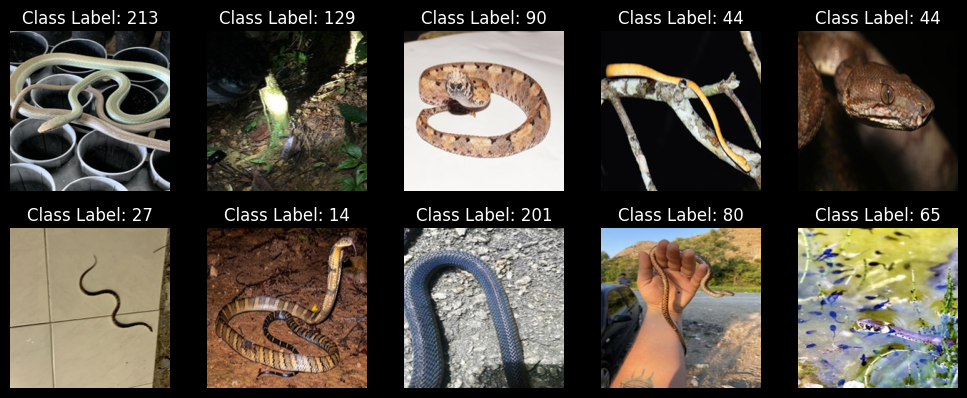

In [13]:
images, labels = train_loader[0]

random_indices = np.random.choice(images.shape[0], size=10, replace=False)

plt.figure(figsize=(10, 10))
for i, idx in enumerate(random_indices):
    ax = plt.subplot(5, 5, i + 1)

    img = images[idx].astype(np.uint8)

    plt.imshow(img)
    plt.title(f"Class Label: {labels[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [15]:
profile = ProfileReport(
    df,
    title="Snake Species Classification Profiling Report",
    vars={
        "num": {"chi_squared_threshold": 0.0}
    },  # Outlierek miatt sok memória fogyasztás
)

profile.to_file("snake_species_classification_profiling_report.html")


Export report to file: 100%|██████████| 1/1 [00:00<00:00, 76.93it/s]
